# ♻️ Residuo Cero · Entrenamiento v2 (datos más variados)

**Por qué una versión 2.** El primer modelo alcanzó 87,9 % en su test, pero esas fotos eran del mismo tipo que las de entrenamiento (TrashNet: un objeto sobre fondo liso). Una prueba con 3.000 fotos de otra fuente mostró que fuera de ese tipo de fotos acertaba solo 47 % en residuos, y fallaba con latas enteras, vidrio y basura. La causa era la poca variedad de los datos (unas 2.900 fotos).

**Qué cambia aquí:**
- Se suman fotos reales de internet (latas, botellas, cartón, papel, plástico, vidrio, zapatos, ropa) a TrashNet y a los objetos de ImageNet.
- El test se mide **por fuente** (TrashNet, internet, ImageNet), para no esconder el rendimiento fuera de TrashNet.
- Se mide también cuántas fotos se clasifican mal **con confianza alta** (la app no avisa en esos casos).
- Se mantienen las mismas 7 clases y el mismo modelo (EfficientNet-B0), así que la app no cambia.

## 0. Librerías y configuración

In [1]:
!pip install -q timm datasets transformers scikit-learn

import os, io, json, hashlib, random, shutil, zipfile, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import torch, torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
import timm
from PIL import Image, ImageOps
from sklearn.model_selection import train_test_split
from sklearn.metrics import (confusion_matrix, ConfusionMatrixDisplay, classification_report,
                             accuracy_score, balanced_accuracy_score)
warnings.filterwarnings("ignore")

SEMILLA = 1993                                     # semilla fija: resultados reproducibles
random.seed(SEMILLA); np.random.seed(SEMILLA); torch.manual_seed(SEMILLA)
DISPOSITIVO = "cuda" if torch.cuda.is_available() else "cpu"
print("Dispositivo:", DISPOSITIVO)

Dispositivo: cuda


## 1. Los datos

| Fuente | Qué aporta | Licencia |
|---|---|---|
| **TrashNet** (Thung y Yang, Stanford, 2016), `garythung/trashnet` | 2.527 fotos de 6 clases, objeto sobre fondo liso | MIT |
| **Fotos de internet**, `UdaraChamidu/Garbage-Classification-with-12-classes` (Hugging Face) | latas, botellas, cartón, papel, plástico, vidrio (3 colores), basura, restos orgánicos, zapatos, ropa y pilas, con fondos y encuadres variados | no declarada; se usa solo con fines educativos |
| **ImageNet-1k** (copia 256x256 de Hugging Face, split de validación) | objetos cotidianos para la clase `other` (calzado, mochilas, electrónicos, muebles, animales, vehículos, paisajes) | términos propios de ImageNet (investigación y educación sin fines comerciales) |

**Cómo se asignan las clases de Residuo Cero:**
- `glass` = vidrio marrón + verde + blanco.
- `trash` = basura de TrashNet y de internet + restos orgánicos (van a la basura general).
- `other` = zapatos, ropa, pilas (no van a un contenedor de reciclaje domiciliario) + objetos de ImageNet.
- Se descartan los duplicados exactos entre fuentes.

**Reservado aparte (no entra a train, val ni test):** 30 zapatos de internet y 40 fotos de 8 categorías de ImageNet que el modelo nunca ve (pizza, castillo, tractor, león, microondas, refrigerador, lavadora y aspiradora).

In [2]:
# [config]
# cuántas fotos se toman de cada carpeta del dataset de internet
TOPE_CARPETA = {"cardboard": 900, "metal": 800, "paper": 900, "plastic": 900,
                "brown-glass": 450, "green-glass": 450, "white-glass": 450,
                "trash": 700, "biological": 300, "shoes": 400, "clothes": 400, "battery": 250}
# a qué clase de Residuo Cero corresponde cada carpeta
CLASE_DE = {"cardboard": "cardboard", "metal": "metal", "paper": "paper", "plastic": "plastic",
            "brown-glass": "glass", "green-glass": "glass", "white-glass": "glass",
            "trash": "trash", "biological": "trash",                      # restos orgánicos -> basura general
            "shoes": "other", "clothes": "other", "battery": "other"}     # pilas: no van a un contenedor domiciliario
TOPE_TRASHNET = None          # None = todas las fotos de TrashNet
N_ZAPATOS_RESERVADOS = 30
POR_CLASE_IN, N_NUNCA_POR_CLASE = 5, 5
LADO_MAX = 384                # las fotos se guardan con el lado mayor de este tamaño (entrena más rápido)
EPOCAS, PACIENCIA, LOTE, TAM, TRABAJADORES = 10, 3, 32, 224, 2
NOMBRES = ["cardboard", "glass", "metal", "other", "paper", "plastic", "trash"]    # orden alfabético, como en la app

In [3]:
# [descarga-trashnet]
from huggingface_hub import hf_hub_download

zip_tn = hf_hub_download("garythung/trashnet", "dataset-resized.zip", repo_type="dataset")   # solo la versión redimensionada
shutil.rmtree("trashnet", ignore_errors=True)
with zipfile.ZipFile(zip_tn) as z:
    z.extractall("trashnet")
RAIZ_TRASHNET = next(r for r, d, _ in os.walk("trashnet")      # carpeta que contiene las 6 carpetas de clase
                     if "__MACOSX" not in r and {"cardboard", "glass", "metal", "paper", "plastic", "trash"} <= set(d))
print("TrashNet:", RAIZ_TRASHNET)

dataset-resized.zip: reconstructing file:   0%|          |  0.00B / 42.8MB            

dataset-resized.zip: downloading bytes:           |  0.00B            

TrashNet: trashnet/dataset-resized


In [4]:
# [descarga-g12]
zip_g12 = hf_hub_download("UdaraChamidu/Garbage-Classification-with-12-classes", "garbage_classification.zip", repo_type="dataset")
print("Dataset de internet:", zip_g12, "·", round(os.path.getsize(zip_g12) / 1e6), "MB")

garbage_classification.zip: reconstructing file:   0%|          |  0.00B /  251MB            

garbage_classification.zip: downloading bytes:           |  0.00B            

Dataset de internet: /root/.cache/huggingface/hub/datasets--UdaraChamidu--Garbage-Classification-with-12-classes/snapshots/1bf81958fc40b7e36080af1a5267c56076c3e450/garbage_classification.zip · 251 MB


In [5]:
# [descarga-imagenet]
from datasets import load_dataset

CARPETA_IN, CARPETA_NUNCA = "imagenet_otro", "otro_nunca_visto"
for c in (CARPETA_IN, CARPETA_NUNCA):
    shutil.rmtree(c, ignore_errors=True); os.makedirs(c)

# clases de ImageNet que sirven como «otro»; se excluyen a propósito las que se parecen a residuos (botellas, latas, cartones, bolsas, libros, tazas)
CLASES_IN = ["running shoe", "sandal", "loafer", "clog", "cowboy boot", "sock", "sweatshirt", "jersey", "jean",
             "cowboy hat", "umbrella", "backpack", "purse", "wallet", "sunglasses", "laptop", "cellular telephone",
             "mouse", "remote control", "computer keyboard", "monitor", "television", "ipod", "digital watch",
             "barber chair", "folding chair", "rocking chair", "studio couch", "desk", "dining table", "table lamp",
             "pillow", "park bench", "golden retriever", "tabby", "egyptian cat", "zebra", "indian elephant",
             "teddy", "acoustic guitar", "electric guitar", "violin", "hammer", "screwdriver", "sports car",
             "mountain bike", "volcano", "valley", "cliff", "coral reef"]
CLASES_NUNCA = ["pizza", "castle", "tractor", "lion", "microwave", "refrigerator", "washer", "vacuum"]

# data_files: baja SOLO los 2 archivos de validación (~670 MB); sin esto baja también train y test (~17 GB)
imnet = load_dataset("benjamin-paine/imagenet-1k-256x256",
                     data_files={"validation": "data/validation-*.parquet"}, split="validation",
                     verification_mode="no_checks")
primer_nombre = [n.split(",")[0].strip().lower() for n in imnet.features["label"].names]
assert len(primer_nombre) >= 1000, len(primer_nombre)          # trae 1001 nombres: una etiqueta extra al final, no afecta
etq_in = np.array(imnet["label"])                              # solo lee la columna de etiquetas
rng_in = np.random.RandomState(SEMILLA)

def guardar_imagenet(nombres, por_clase, carpeta, prefijo):
    total = 0
    for nombre in nombres:
        k = primer_nombre.index(nombre)
        for j in rng_in.choice(np.where(etq_in == k)[0], por_clase, replace=False):
            imnet[int(j)]["image"].convert("RGB").save(f"{carpeta}/{prefijo}_{k}_{j}.jpg", quality=92)
            total += 1
    return total

n_in = guardar_imagenet(CLASES_IN, POR_CLASE_IN, CARPETA_IN, "in")
n_nunca = guardar_imagenet(CLASES_NUNCA, N_NUNCA_POR_CLASE, CARPETA_NUNCA, "nunca")
del imnet
print(f"ImageNet: {n_in} fotos para «other» · {n_nunca} fotos de categorías nunca vistas")

README.md:   0%|          | 0.00/88.1k [00:00<?, ?B/s]

data/validation-00000-of-00002.parquet: reconstructing file:   0%|          |  0.00B /  352MB            

data/validation-00000-of-00002.parquet: downloading bytes:           |  0.00B            

data/validation-00001-of-00002.parquet: reconstructing file:   0%|          |  0.00B /  351MB            

data/validation-00001-of-00002.parquet: downloading bytes:           |  0.00B            

Generating validation split:   0%|          | 0/50000 [00:00<?, ? examples/s]

ImageNet: 250 fotos para «other» · 40 fotos de categorías nunca vistas


### 1.1 Juntar todo en una sola carpeta
Cada foto se guarda redimensionada en `datos/<clase>/`, se descartan los duplicados exactos (misma foto en dos fuentes) y se anota de qué fuente viene, para poder medir el rendimiento por fuente más adelante.

In [6]:
# [construir-datos]
CARPETA_DATOS, CARPETA_ZAPATOS = "datos", "zapatos_reservados"
for c in (CARPETA_DATOS, CARPETA_ZAPATOS):
    shutil.rmtree(c, ignore_errors=True); os.makedirs(c)
for n in NOMBRES:
    os.makedirs(os.path.join(CARPETA_DATOS, n))

rng = random.Random(SEMILLA)
vistos = set()        # huellas de las fotos ya guardadas: evita duplicados exactos entre fuentes
filas = []            # (ruta, clase, fuente)

def guardar(contenido, destino):
    """Guarda la foto con el lado mayor <= LADO_MAX. Devuelve False si es un duplicado exacto o no se puede leer."""
    h = hashlib.md5(contenido).hexdigest()
    if h in vistos:
        return False
    try:
        img = Image.open(io.BytesIO(contenido))
        img.draft("RGB", (LADO_MAX * 2, LADO_MAX * 2))
        img = ImageOps.exif_transpose(img).convert("RGB")
        img.thumbnail((LADO_MAX, LADO_MAX))
        img.save(destino, quality=90)
    except Exception:
        return False
    vistos.add(h)
    return True

# --- fuente 1: TrashNet
for clase in ["cardboard", "glass", "metal", "paper", "plastic", "trash"]:
    archivos = sorted(os.listdir(os.path.join(RAIZ_TRASHNET, clase)))
    if TOPE_TRASHNET:
        rng.shuffle(archivos); archivos = archivos[:TOPE_TRASHNET]
    for k, f in enumerate(archivos):
        destino = os.path.join(CARPETA_DATOS, clase, f"trashnet_{k}.jpg")
        with open(os.path.join(RAIZ_TRASHNET, clase, f), "rb") as fh:
            if guardar(fh.read(), destino):
                filas.append((destino, clase, "trashnet"))

# --- fuente 2: fotos de internet (12 carpetas -> clases de Residuo Cero)
z = zipfile.ZipFile(zip_g12)
miembros = {}
for n in z.namelist():
    p = n.split("/")
    if len(p) >= 2 and p[-2] in CLASE_DE and n.lower().endswith((".jpg", ".jpeg", ".png", ".webp")):
        miembros.setdefault(p[-2], []).append(n)
reservados = []
for carpeta, nombres in miembros.items():
    nombres = sorted(nombres); rng.shuffle(nombres)
    if carpeta == "shoes":                                   # estos zapatos no entran a train, val ni test
        reservados, nombres = nombres[:N_ZAPATOS_RESERVADOS], nombres[N_ZAPATOS_RESERVADOS:]
    clase, guardadas = CLASE_DE[carpeta], 0
    for n in nombres:
        if guardadas >= TOPE_CARPETA[carpeta]:
            break
        destino = os.path.join(CARPETA_DATOS, clase, f"web_{carpeta}_{guardadas}.jpg")
        if guardar(z.read(n), destino):
            filas.append((destino, clase, "web")); guardadas += 1
for k, n in enumerate(reservados):                           # se guardan al final: así nunca repiten una foto de entrenamiento
    guardar(z.read(n), os.path.join(CARPETA_ZAPATOS, f"zapato_{k}.jpg"))

# --- fuente 3: ImageNet (solo para «other»)
for f in sorted(os.listdir(CARPETA_IN)):
    destino = os.path.join(CARPETA_DATOS, "other", f"imagenet_{f}")
    with open(os.path.join(CARPETA_IN, f), "rb") as fh:
        if guardar(fh.read(), destino):
            filas.append((destino, "other", "imagenet"))

df = pd.DataFrame(filas, columns=["ruta", "clase", "fuente"])
etiquetas = df["clase"].map({n: i for i, n in enumerate(NOMBRES)}).values
print(pd.crosstab(df["clase"], df["fuente"], margins=True))
print(f"\nZapatos reservados: {len(os.listdir(CARPETA_ZAPATOS))} · fotos «nunca vistas»: {len(os.listdir(CARPETA_NUNCA))}")

fuente     imagenet  trashnet   web   All
clase                                    
cardboard         0       403   488   891
glass             0       501  1350  1851
metal             0       409   359   768
other           250         0  1050  1300
paper             0       594   456  1050
plastic           0       480   387   867
trash             0       137   997  1134
All             250      2524  5087  7861

Zapatos reservados: 30 · fotos «nunca vistas»: 40


### 1.2 Fotos por clase y desbalance

cardboard :   891  (11.3%)
glass     :  1851  (23.5%)
metal     :   768  (9.8%)
other     :  1300  (16.5%)
paper     :  1050  (13.4%)
plastic   :   867  (11.0%)
trash     :  1134  (14.4%)
Razón mayor / menor clase: 2.4


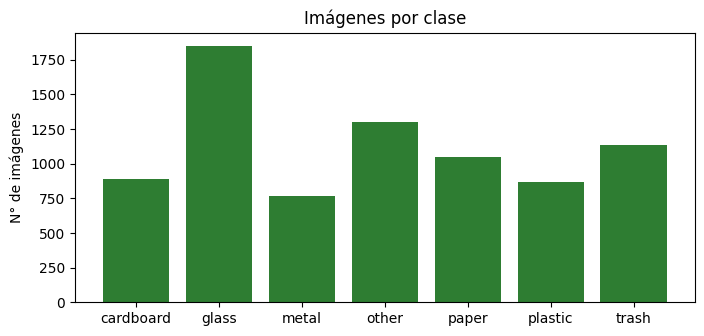

In [7]:
conteo = df["clase"].value_counts().reindex(NOMBRES)
for n, c in conteo.items():
    print(f"{n:10s}: {c:5d}  ({c / conteo.sum():.1%})")
print("Razón mayor / menor clase:", round(conteo.max() / conteo.min(), 1))

plt.figure(figsize=(8, 3.5))
plt.bar(NOMBRES, conteo.values, color="#2e7d32")
plt.title("Imágenes por clase"); plt.ylabel("N° de imágenes"); plt.show()

### 1.3 Ejemplos de cada clase

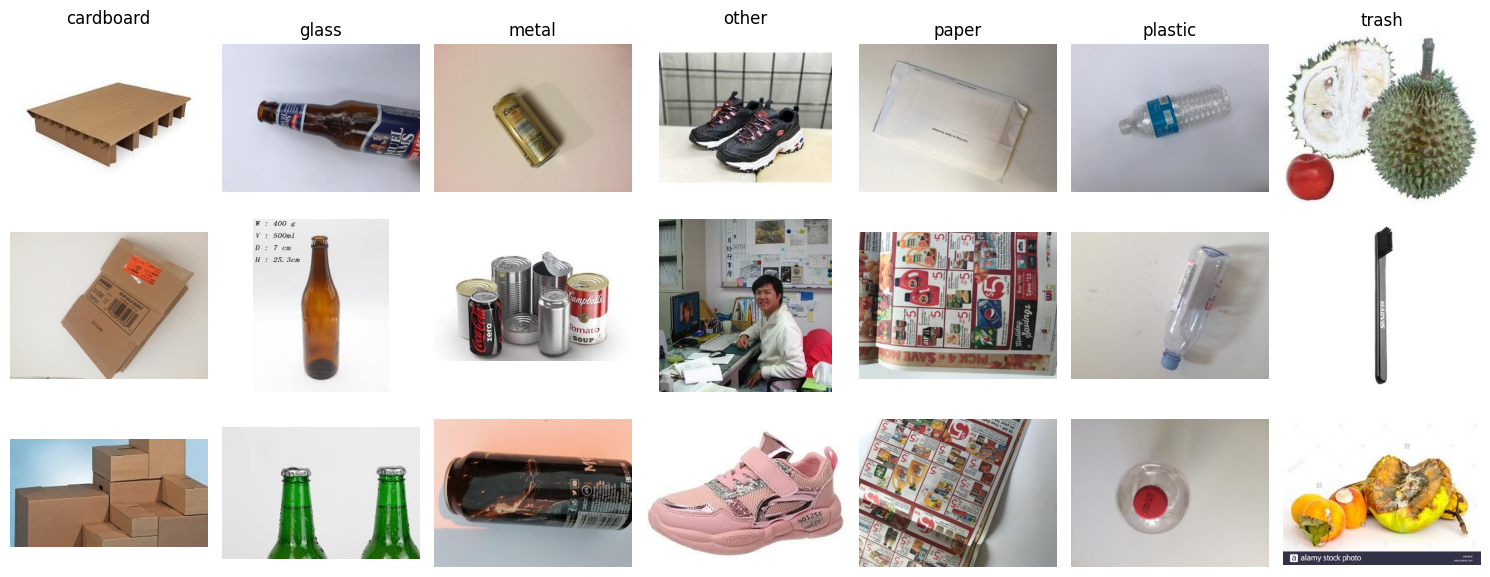

In [8]:
plt.figure(figsize=(15, 6))
for k, n in enumerate(NOMBRES):
    for j, ruta in enumerate(df[df["clase"] == n].sample(3, random_state=SEMILLA)["ruta"]):
        plt.subplot(3, len(NOMBRES), j * len(NOMBRES) + k + 1)
        plt.imshow(Image.open(ruta)); plt.axis("off")
        if j == 0:
            plt.title(n)
plt.tight_layout(); plt.show()

### 1.4 División train / val / test
Estratificada por clase **y** por fuente (70 % / 15 % / 15 %), para que cada fuente esté representada en el test.

In [9]:
# [division]
estrato = (df["clase"] + "|" + df["fuente"]).values
indices = np.arange(len(df))
i_train, i_resto = train_test_split(indices, test_size=0.30, stratify=estrato, random_state=SEMILLA)
i_val, i_test = train_test_split(i_resto, test_size=0.50, stratify=estrato[i_resto], random_state=SEMILLA)
df["division"] = ""
df.loc[i_train, "division"], df.loc[i_val, "division"], df.loc[i_test, "division"] = "train", "val", "test"

print(pd.crosstab(df["clase"], df["division"], margins=True)[["train", "val", "test", "All"]])
print()
print(pd.crosstab(df["fuente"], df["division"], margins=True)[["train", "val", "test", "All"]])

division   train   val  test   All
clase                             
cardboard    623   134   134   891
glass       1296   277   278  1851
metal        537   116   115   768
other        910   195   195  1300
paper        735   157   158  1050
plastic      607   130   130   867
trash        794   170   170  1134
All         5502  1179  1180  7861

division  train   val  test   All
fuente                           
imagenet    175    38    37   250
trashnet   1767   380   377  2524
web        3560   761   766  5087
All        5502  1179  1180  7861


**✏️ Limitaciones de los datos (para la ficha y la exposición):**
- **Etiquetas ruidosas en las fotos de internet:** vienen de buscadores y pueden tener errores; su carpeta «trash» no se define igual que la de TrashNet.
- **Casi-duplicados:** solo se eliminan copias exactas. El dataset de internet tiene muchas fotos casi iguales, así que parte del test puede parecerse a train y el resultado de esa fuente puede ser algo optimista.
- **`trash` agrupa cosas muy distintas** (basura de TrashNet, basura de internet y restos orgánicos).
- **`other` es una mezcla:** zapatos, ropa, pilas y objetos de ImageNet. No cubre todos los objetos posibles (por ejemplo, madera no está).
- **Envases de otros países:** gran parte de las fotos no corresponde a productos chilenos.
- **Licencias:** TrashNet es MIT; las fotos de internet no declaran licencia y ImageNet tiene términos propios. Se usan solo con fines educativos.

## 2. Preparar los datos para PyTorch

In [10]:
# [torch-datos]
MEDIA, DESV = [0.485, 0.456, 0.406], [0.229, 0.224, 0.225]   # estadísticas de ImageNet

tf_train = transforms.Compose([
    transforms.RandomResizedCrop(TAM, scale=(0.6, 1.0)),      # recorte aleatorio
    transforms.RandomHorizontalFlip(),                        # volteo horizontal
    transforms.RandomRotation(15),                            # rotación leve
    transforms.ColorJitter(0.3, 0.3, 0.3),                    # brillo, contraste, saturación
    transforms.ToTensor(), transforms.Normalize(MEDIA, DESV)])
tf_eval = transforms.Compose([                                # sin azar en val ni test
    transforms.Resize((TAM, TAM)),
    transforms.ToTensor(), transforms.Normalize(MEDIA, DESV)])

class Residuos(Dataset):
    def __init__(self, indices, tf):
        self.indices, self.tf = indices, tf
    def __len__(self):
        return len(self.indices)
    def __getitem__(self, k):
        i = int(self.indices[k])
        return self.tf(Image.open(df["ruta"].iloc[i]).convert("RGB")), int(etiquetas[i])

dl_train = DataLoader(Residuos(i_train, tf_train), batch_size=LOTE, shuffle=True, num_workers=TRABAJADORES)
dl_val = DataLoader(Residuos(i_val, tf_eval), batch_size=LOTE, num_workers=TRABAJADORES)
dl_test = DataLoader(Residuos(i_test, tf_eval), batch_size=LOTE, num_workers=TRABAJADORES)

## 3. Evaluación común

In [11]:
y_test = etiquetas[i_test]                                    # etiquetas reales del test

def evaluar(pred, nombre):
    acc = accuracy_score(y_test, pred)
    bal = balanced_accuracy_score(y_test, pred)
    print(f"{nombre}: accuracy = {acc:.3f} · accuracy balanceada = {bal:.3f}")
    return acc, bal

## 4. Línea base · CLIP sin entrenar (zero-shot)

In [12]:
# [clip]
from transformers import CLIPModel, CLIPProcessor

clip = CLIPModel.from_pretrained("openai/clip-vit-base-patch32").to(DISPOSITIVO).eval()
proc = CLIPProcessor.from_pretrained("openai/clip-vit-base-patch32")

FRASES = {"cardboard": "a photo of cardboard waste", "glass": "a photo of glass waste", "metal": "a photo of metal waste",
          "other": "a photo of an everyday object that is not waste", "paper": "a photo of paper waste",
          "plastic": "a photo of plastic waste", "trash": "a photo of general trash"}
frases = [FRASES[n] for n in NOMBRES]
rutas_test = df["ruta"].iloc[i_test].tolist()

pred_clip = []
with torch.no_grad():
    for i in range(0, len(rutas_test), 32):
        fotos = [Image.open(r).convert("RGB") for r in rutas_test[i:i + 32]]
        entrada = proc(text=frases, images=fotos, return_tensors="pt", padding=True).to(DISPOSITIVO)
        pred_clip += clip(**entrada).logits_per_image.argmax(dim=1).cpu().tolist()
pred_clip = np.array(pred_clip)

acc_clip, bal_clip = evaluar(pred_clip, "CLIP zero-shot")
del clip; torch.cuda.empty_cache()

config.json:   0%|          | 0.00/4.19k [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  605MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  605MB            

...

vocab.json:   0%|          | 0.00/862k [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/525k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/2.22M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/389 [00:00<?, ?B/s]

CLIP zero-shot: accuracy = 0.584 · accuracy balanceada = 0.551


## 5. Modelo principal · EfficientNet-B0 con *transfer learning* (timm)

In [13]:
modelo = timm.create_model("efficientnet_b0", pretrained=True, num_classes=len(NOMBRES)).to(DISPOSITIVO)

pesos = torch.tensor(len(i_train) / (len(NOMBRES) * np.bincount(etiquetas[i_train], minlength=len(NOMBRES))), dtype=torch.float32)
print("Peso por clase:", {n: round(float(p), 2) for n, p in zip(NOMBRES, pesos)})      # más peso a la clase escasa

perdida = nn.CrossEntropyLoss(weight=pesos.to(DISPOSITIVO))
optim = torch.optim.AdamW(modelo.parameters(), lr=1e-4)                                # tasa de aprendizaje pequeña

model.safetensors: reconstructing file:   0%|          |  0.00B / 21.4MB            

model.safetensors: downloading bytes:           |  0.00B            

Peso por clase: {'cardboard': 1.26, 'glass': 0.61, 'metal': 1.46, 'other': 0.86, 'paper': 1.07, 'plastic': 1.29, 'trash': 0.99}


In [14]:
# [entrenar]
def predecir(dl):
    modelo.eval(); todas = []
    with torch.no_grad():
        for x, _ in dl:
            todas.append(torch.softmax(modelo(x.to(DISPOSITIVO)), dim=1).cpu())
    return torch.cat(todas).numpy()                                                    # probabilidades por clase

y_val = etiquetas[i_val]
historia = {"loss": [], "val_bal": []}
mejor, sin_mejora = 0, 0

for ep in range(EPOCAS):
    modelo.train(); acumulada = 0
    for x, y_lote in dl_train:
        x, y_lote = x.to(DISPOSITIVO), y_lote.to(DISPOSITIVO)
        optim.zero_grad()
        l = perdida(modelo(x), y_lote)
        l.backward(); optim.step()
        acumulada += l.item() * len(x)
    val_bal = balanced_accuracy_score(y_val, predecir(dl_val).argmax(1))               # se mide en VALIDACIÓN, no en test
    historia["loss"].append(acumulada / len(i_train)); historia["val_bal"].append(val_bal)
    print(f"Época {ep + 1}/{EPOCAS} · pérdida train {historia['loss'][-1]:.3f} · accuracy balanceada val {val_bal:.3f}")
    if val_bal > mejor:                                                                # guarda el mejor modelo
        mejor, sin_mejora = val_bal, 0
        torch.save(modelo.state_dict(), "mejor.pt")
    else:
        sin_mejora += 1
        if sin_mejora >= PACIENCIA:
            print("Parada temprana: la validación dejó de mejorar."); break

modelo.load_state_dict(torch.load("mejor.pt"))                                         # vuelve al mejor modelo

Época 1/10 · pérdida train 1.322 · accuracy balanceada val 0.800
Época 2/10 · pérdida train 0.488 · accuracy balanceada val 0.860
Época 3/10 · pérdida train 0.316 · accuracy balanceada val 0.878
Época 4/10 · pérdida train 0.205 · accuracy balanceada val 0.889
Época 5/10 · pérdida train 0.154 · accuracy balanceada val 0.906
Época 6/10 · pérdida train 0.109 · accuracy balanceada val 0.903
Época 7/10 · pérdida train 0.107 · accuracy balanceada val 0.920
Época 8/10 · pérdida train 0.085 · accuracy balanceada val 0.915
Época 9/10 · pérdida train 0.068 · accuracy balanceada val 0.924
Época 10/10 · pérdida train 0.069 · accuracy balanceada val 0.923


<All keys matched successfully>

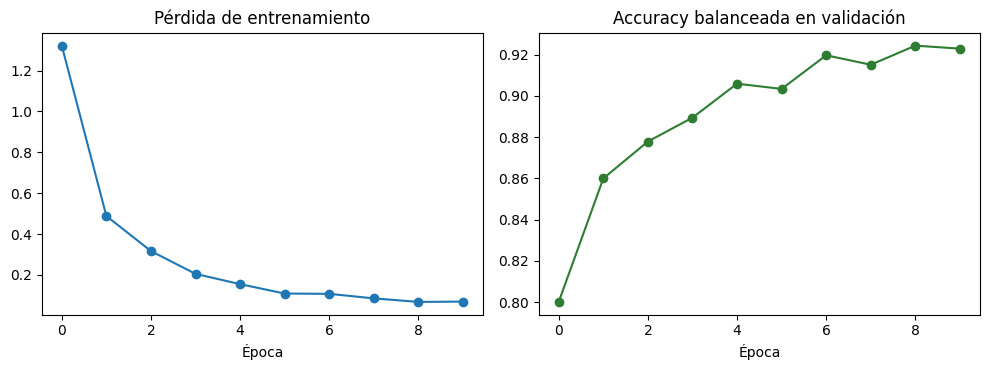

In [15]:
fig, ax = plt.subplots(1, 2, figsize=(10, 3.8))
ax[0].plot(historia["loss"], marker="o"); ax[0].set_title("Pérdida de entrenamiento"); ax[0].set_xlabel("Época")
ax[1].plot(historia["val_bal"], marker="o", color="#2e7d32"); ax[1].set_title("Accuracy balanceada en validación"); ax[1].set_xlabel("Época")
plt.tight_layout(); plt.show()

**✏️ ¿Hay overfitting?** Las 10 épocas se completaron sin que se activara la parada temprana. La pérdida de entrenamiento baja de 1,32 a 0,07 y la accuracy balanceada de validación sube de 0,80 a 0,92 (máximo de 0,924 en la época 9). No se ve overfitting claro, porque la validación no cae. Ojo: el dataset de internet tiene fotos casi iguales entre sí, así que la validación y el test pueden ser algo optimistas; por eso se hicieron las pruebas independientes de la sección 6.4.

## 6. Resultados en el conjunto de **prueba**

In [16]:
prob_test = predecir(dl_test)
pred_eff = prob_test.argmax(1)

acc_eff, bal_eff = evaluar(pred_eff, "EfficientNet-B0")
acc_clip, bal_clip = evaluar(pred_clip, "CLIP zero-shot (línea base)")
print()
print(classification_report(y_test, pred_eff, labels=range(len(NOMBRES)), target_names=NOMBRES, digits=3))

EfficientNet-B0: accuracy = 0.930 · accuracy balanceada = 0.931
CLIP zero-shot (línea base): accuracy = 0.584 · accuracy balanceada = 0.551

              precision    recall  f1-score   support

   cardboard      0.929     0.970     0.949       134
       glass      0.963     0.942     0.953       278
       metal      0.816     0.965     0.884       115
       other      0.967     0.897     0.931       195
       paper      0.944     0.962     0.953       158
     plastic      0.899     0.892     0.896       130
       trash      0.938     0.888     0.912       170

    accuracy                          0.930      1180
   macro avg      0.922     0.931     0.925      1180
weighted avg      0.932     0.930     0.930      1180



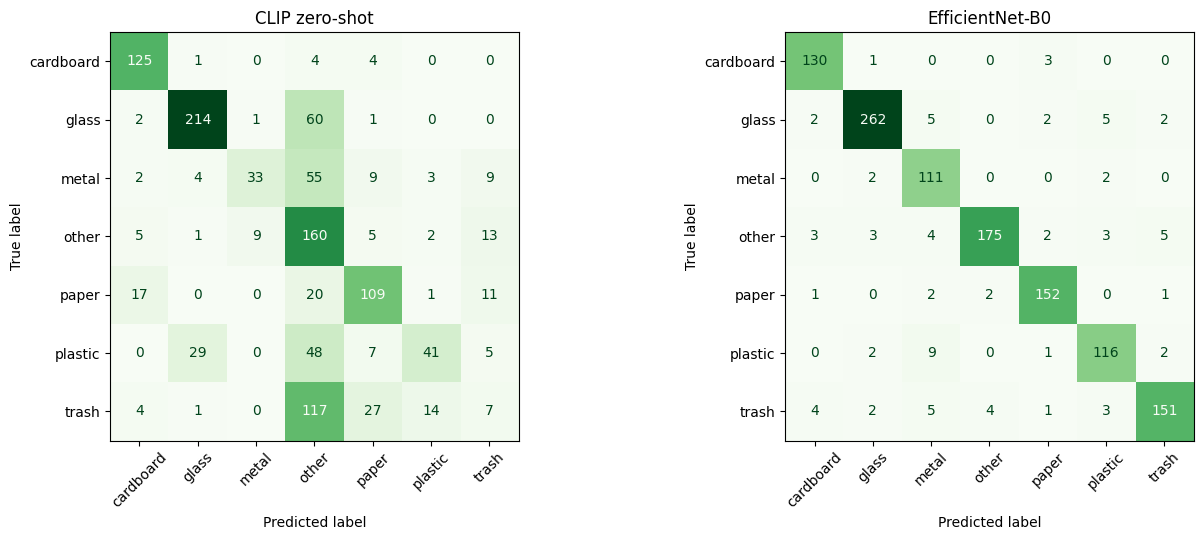

In [17]:
fig, ax = plt.subplots(1, 2, figsize=(14, 5.5))
for a, pred, titulo in [(ax[0], pred_clip, "CLIP zero-shot"), (ax[1], pred_eff, "EfficientNet-B0")]:
    ConfusionMatrixDisplay(confusion_matrix(y_test, pred, labels=range(len(NOMBRES))), display_labels=NOMBRES).plot(ax=a, cmap="Greens", colorbar=False)
    a.set_title(titulo); a.tick_params(axis="x", rotation=45)
plt.tight_layout(); plt.show()
cm = confusion_matrix(y_test, pred_eff, labels=range(len(NOMBRES)))

### 6.0 Rendimiento por fuente
Lo más importante de esta versión: ¿funciona igual de bien con fotos de internet que con las de TrashNet?

In [18]:
fuente_test = df["fuente"].iloc[i_test].values
acc_fuente = {}
for f in ["trashnet", "web", "imagenet"]:
    m = fuente_test == f
    if m.any():
        acc_fuente[f] = float(np.mean(pred_eff[m] == y_test[m]))
        print(f"Fotos de «{f}» en el test: {m.sum():4d} · accuracy = {acc_fuente[f]:.3f}")

print("\nRecall por clase y fuente:")
for n in NOMBRES:
    k = NOMBRES.index(n)
    partes = []
    for f in ["trashnet", "web", "imagenet"]:
        m = (fuente_test == f) & (y_test == k)
        if m.any():
            partes.append(f"{f} {np.mean(pred_eff[m] == k):.0%} (n={m.sum()})")
    print(f"  {n:10s} " + " · ".join(partes))

Fotos de «trashnet» en el test:  377 · accuracy = 0.910
Fotos de «web» en el test:  766 · accuracy = 0.949
Fotos de «imagenet» en el test:   37 · accuracy = 0.730

Recall por clase y fuente:
  cardboard  trashnet 93% (n=60) · web 100% (n=74)
  glass      trashnet 91% (n=75) · web 96% (n=203)
  metal      trashnet 97% (n=61) · web 96% (n=54)
  other      web 94% (n=158) · imagenet 73% (n=37)
  paper      trashnet 96% (n=89) · web 97% (n=69)
  plastic    trashnet 83% (n=72) · web 97% (n=58)
  trash      trashnet 75% (n=20) · web 91% (n=150)


### 6.1 ¿Cuándo desconfiar? Confianza de las predicciones

In [19]:
confianza = prob_test.max(1)
correcto = pred_eff == y_test
print(f"Confianza media cuando acierta: {confianza[correcto].mean():.2f} · cuando se equivoca: {confianza[~correcto].mean():.2f}")
for umbral in (0.5, 0.6, 0.7, 0.8, 0.9):
    m = confianza >= umbral
    print(f"Confianza ≥ {umbral:.1f}: {m.mean():.0%} de las fotos · accuracy en ese grupo = {correcto[m].mean():.3f}")

fallas_sin_aviso = float(np.mean((~correcto) & (confianza >= 0.70)))
print(f"\nFotos mal clasificadas con confianza ≥ 0,70 (la app NO avisa): {fallas_sin_aviso:.1%} del test")

Confianza media cuando acierta: 0.97 · cuando se equivoca: 0.75
Confianza ≥ 0.5: 98% de las fotos · accuracy en ese grupo = 0.938
Confianza ≥ 0.6: 96% de las fotos · accuracy en ese grupo = 0.945
Confianza ≥ 0.7: 94% de las fotos · accuracy en ese grupo = 0.957
Confianza ≥ 0.8: 92% de las fotos · accuracy en ese grupo = 0.965
Confianza ≥ 0.9: 88% de las fotos · accuracy en ese grupo = 0.976

Fotos mal clasificadas con confianza ≥ 0,70 (la app NO avisa): 4.1% del test


### 6.2 ¿Dónde se equivocó?

Errores: 83 de 1180


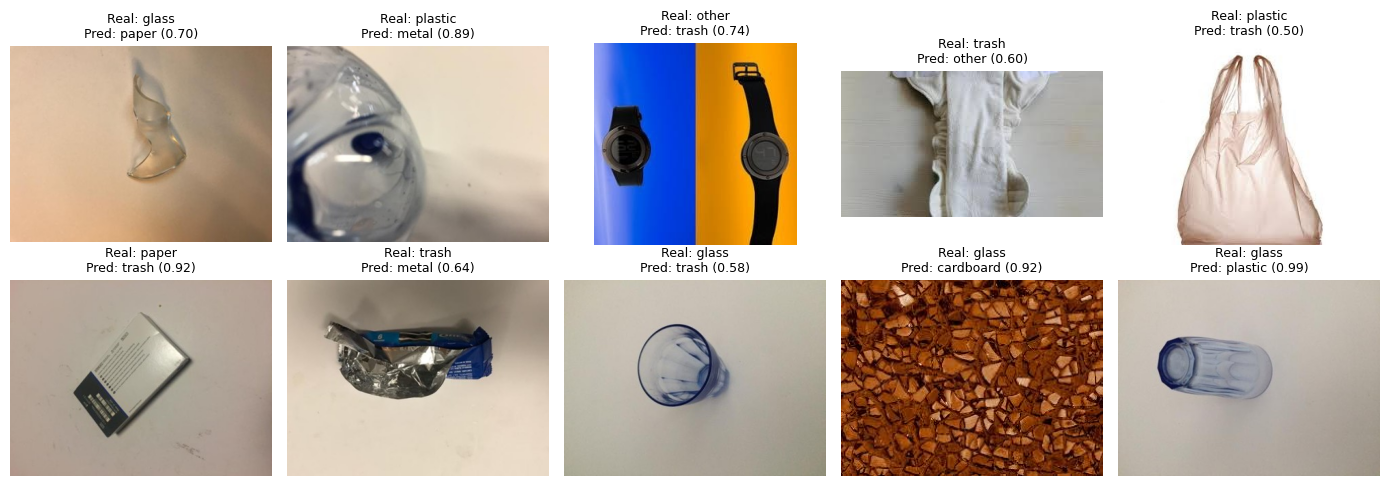

In [20]:
errores = np.where(~correcto)[0]
print("Errores:", len(errores), "de", len(y_test))
plt.figure(figsize=(14, 5))
for k, e in enumerate(errores[:10]):
    plt.subplot(2, 5, k + 1)
    plt.imshow(Image.open(rutas_test[e])); plt.axis("off")
    plt.title(f"Real: {NOMBRES[y_test[e]]}\nPred: {NOMBRES[pred_eff[e]]} ({confianza[e]:.2f})", fontsize=9)
plt.tight_layout(); plt.show()

### 6.3 Objetos que no son residuos
Zapatos reservados (nunca entraron a train, val ni test) y categorías de ImageNet que el modelo nunca vio.

In [21]:
k_otro = NOMBRES.index("other")

def predecir_carpeta(carpeta):
    fotos = [Image.open(os.path.join(carpeta, f)).convert("RGB") for f in sorted(os.listdir(carpeta))]
    modelo.eval(); probs = []
    with torch.no_grad():
        for i in range(0, len(fotos), 32):
            x = torch.stack([tf_eval(f) for f in fotos[i:i + 32]]).to(DISPOSITIVO)
            probs.append(torch.softmax(modelo(x), dim=1).cpu())
    return torch.cat(probs).numpy()

recall_otro = cm[k_otro, k_otro] / cm[k_otro].sum()
print(f"Recall de 'other' en test: {recall_otro:.1%}")
falsos_otro = cm[:, k_otro].sum() - cm[k_otro, k_otro]
print(f"Residuos reales clasificados como 'other' en el test: {falsos_otro} de {(y_test != k_otro).sum()} ({falsos_otro / (y_test != k_otro).sum():.1%})")

p_zap, p_nv = predecir_carpeta(CARPETA_ZAPATOS), predecir_carpeta(CARPETA_NUNCA)
pct_zapatos = float((p_zap.argmax(1) == k_otro).mean())
pct_nunca = float((p_nv.argmax(1) == k_otro).mean())
print(f"Zapatos reservados detectados como 'other': {pct_zapatos:.1%} ({(p_zap.argmax(1) == k_otro).sum()} de {len(p_zap)})")
print(f"Categorías nunca vistas detectadas como 'other': {pct_nunca:.1%} ({(p_nv.argmax(1) == k_otro).sum()} de {len(p_nv)})")
print("Clases elegidas para las categorías nunca vistas:", {NOMBRES[k]: int(v) for k, v in zip(*np.unique(p_nv.argmax(1), return_counts=True))})

Recall de 'other' en test: 89.7%
Residuos reales clasificados como 'other' en el test: 6 de 985 (0.6%)
Zapatos reservados detectados como 'other': 100.0% (30 de 30)
Categorías nunca vistas detectadas como 'other': 62.5% (25 de 40)
Clases elegidas para las categorías nunca vistas: {'cardboard': 2, 'metal': 3, 'other': 25, 'paper': 4, 'plastic': 1, 'trash': 5}


### 6.4 Pruebas independientes (hechas fuera del notebook)
Las pruebas anteriores usan fotos de las mismas fuentes que el entrenamiento. Para saber cómo funciona con fotos realmente nuevas se hicieron tres pruebas más; los scripts están en la carpeta `pruebas/` del repositorio.

| Prueba | Modelo anterior (solo TrashNet + 400 «otro») | **Modelo nuevo (este notebook)** |
|---|---|---|
| 1.374 fotos de internet que este notebook nunca usó (vidrio, zapatos, ropa, pilas, restos orgánicos) | 59,8 % | **94,6 %** |
| 77 fotos de residuos de Wikimedia Commons (latas, botellas, vidrio, cartón, papel) | 57,1 % | **81,8 %** |
| 154 fotos de objetos que no son residuos de Wikimedia Commons (madera, zapatos, mochilas, laptops, sillas, gatos, bicicletas, flores) | 61,0 % | **72,1 %** |

- **Detalle de Wikimedia Commons (modelo nuevo):** latas 65 %, botellas de plástico 79 %, vidrio 80 %, cartón 94 %, papel 100 %, madera 64 %.
- **Errores sin aviso:** en esas fotos de residuos, el modelo nuevo se equivoca con confianza de 70 % o más en el 14,3 % de los casos (el anterior, 15,6 %).
- **Fiabilidad:** son pocas fotos (77 de residuos), así que cada cifra tiene unos ±10 puntos de margen. Las fotos se eligieron a ojo, buscando que el objeto fuera el protagonista, **antes** de ver ninguna predicción.
- **Hallazgo sobre los datos:** el dataset de internet de 12 clases **incluye las fotos de TrashNet** (idénticas byte a byte: el 45 % de su carpeta de cartón, el 53 % de metal, el 57 % de papel y el 55 % de plástico). Por eso este notebook elimina los duplicados exactos entre fuentes antes de dividir los datos. Una prueba externa anterior que usó ese dataset sin quitar esas copias sobreestimaba el acierto del modelo anterior (47 % en lugar de 22 % en las fotos realmente nuevas).

## 7. Exportar para la app

In [22]:
# [exportar]
recall = {n: float(cm[k, k] / cm[k].sum()) for k, n in enumerate(NOMBRES)}
os.makedirs("modelo", exist_ok=True)
torch.save(modelo.state_dict(), "modelo/modelo_efficientnet.pt")
json.dump(NOMBRES, open("modelo/clases.json", "w"), ensure_ascii=False)
json.dump({
    "accuracy": float(acc_eff), "accuracy_balanceada": float(bal_eff), "n_test": int(len(y_test)),
    "recall_por_clase": recall, "clip_accuracy": float(acc_clip), "clip_accuracy_balanceada": float(bal_clip),
    "otro_zapatos_nunca_vistos": pct_zapatos, "otro_categorias_nunca_vistas": pct_nunca,
    "accuracy_por_fuente": acc_fuente, "fallas_con_confianza_alta": fallas_sin_aviso,
}, open("modelo/metricas.json", "w"), ensure_ascii=False, indent=2)
print("Tamaño de los pesos:", round(os.path.getsize("modelo/modelo_efficientnet.pt") / 1e6, 1), "MB (GitHub acepta hasta 100 MB)")

# una imagen de ejemplo por clase: la del test que el modelo acierta con más seguridad (así el ejemplo de la demo siempre funciona)
os.makedirs("ejemplos", exist_ok=True)
for k, n in enumerate(NOMBRES):
    cand = [j for j in range(len(y_test)) if y_test[j] == k and pred_eff[j] == k] or [j for j in range(len(y_test)) if y_test[j] == k]
    mejor_j = max(cand, key=lambda j: confianza[j])
    Image.open(rutas_test[mejor_j]).convert("RGB").resize((384, 384)).save(f"ejemplos/{n}.jpg")
# un zapato reservado que el modelo detecte como «other»
for j, f in enumerate(sorted(os.listdir(CARPETA_ZAPATOS))):
    if p_zap[j].argmax() == k_otro:
        Image.open(os.path.join(CARPETA_ZAPATOS, f)).convert("RGB").resize((384, 384)).save("ejemplos/zapato.jpg")
        break

# todo en un zip para subirlo a GitHub
shutil.rmtree("entrega", ignore_errors=True); os.makedirs("entrega")
shutil.copytree("modelo", "entrega/modelo"); shutil.copytree("ejemplos", "entrega/ejemplos")
shutil.make_archive("entrega_modelo_v2", "zip", "entrega")
try:
    from google.colab import files
    files.download("entrega_modelo_v2.zip")
except ImportError:
    print("(fuera de Colab: el zip quedó en", os.path.abspath("entrega_modelo_v2.zip"), ")")

Tamaño de los pesos: 16.4 MB (GitHub acepta hasta 100 MB)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 8. Conclusiones

- **Modelo:** EfficientNet-B0 con transfer learning alcanzó 93,0 % de accuracy y 93,1 % de accuracy balanceada en test (1.180 fotos), contra 58,4 % y 55,1 % de CLIP sin entrenar. Ganó por 34,6 puntos de accuracy.
- **Por fuente:** TrashNet 91,0 %, fotos de internet 94,9 % e ImageNet 73,0 %. Las fotos de internet tienen casi-duplicados entre sí, así que ese 94,9 % puede ser algo optimista.
- **Clases:** el recall va de 89 % a 97 %. Las más difíciles son `trash` (88,8 %), `plastic` (89,2 %) y `other` (89,7 %); las mejores, `cardboard` (97,0 %) y `metal` (96,5 %).
- **Error más costoso:** que `trash` pase por reciclable contamina el lote: ocurrió con 15 de 170 fotos (8,8 %). El error inverso también cuesta: 5 de 815 reciclables se clasificaron como `trash` y 2 como `other`.
- **Confianza:** el 94 % de las fotos tiene confianza de 0,7 o más y en ese grupo el accuracy es 95,7 %. El 4,1 % del test se clasifica mal con confianza alta, y en esos casos la app no avisa.
- **Objetos que no son residuos:** los 30 zapatos reservados se detectaron como `other`, y 25 de las 40 fotos de categorías nunca vistas (62,5 %).
- **Pruebas independientes (6.4):** con fotos realmente nuevas el modelo acierta cerca de 82 % en residuos y 72 % en objetos que no lo son. La estimación realista para fotos nuevas es de alrededor de 80 % en residuos, no el 93 % del test.
- **Limitaciones:** etiquetas ruidosas y fotos casi duplicadas en el dataset de internet, latas enteras confundidas con vidrio o plástico (65 % de acierto), flores y plantas clasificadas como `trash`, pocas fotos de ImageNet para `other` (73 %), envases que no son chilenos y PNG con fondo transparente que la app lee con fondo negro.
- **Mejoras futuras:** más fotos propias con fondos reales y envases chilenos, más variedad en `other` (plantas, madera, objetos de oficina), reentrenar con ellas y probar con un conjunto de fotos propias del equipo.

> ⚠️ Prototipo educativo: no reemplaza las indicaciones de la municipalidad ni de un punto limpio.